In [ ]:
import os, math, time, random, zipfile, shutil, json
from pathlib import Path
from PIL import Image, ImageOps, UnidentifiedImageError
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms
from torchvision.utils import make_grid, save_image

In [ ]:
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print(torch.cuda.get_device_name(0))

Device: cuda
NVIDIA A100-SXM4-40GB


In [ ]:
DATA_ZIP = "/content/cosmetics_images.zip"  # e.g. uploaded ZIP in Colab; set to "" if not using ZIP
IMAGE_ROOT = "/content/cosmetics_images"    # folder containing images (searched recursively)

from google.colab import files
uploaded = files.upload()
DATA_ZIP = next(iter(uploaded.keys()))

EXTRACT_ROOT = "/content/cosmetics_dataset"
if DATA_ZIP and os.path.isfile(DATA_ZIP):
    os.makedirs(EXTRACT_ROOT, exist_ok=True)
    with zipfile.ZipFile(DATA_ZIP, "r") as zf:
        # Basic path traversal protection
        root_abs = os.path.abspath(EXTRACT_ROOT)
        for member in zf.infolist():
            target = os.path.abspath(os.path.join(EXTRACT_ROOT, member.filename))
            if target == root_abs or target.startswith(root_abs + os.sep):
                zf.extract(member, EXTRACT_ROOT)
    IMAGE_ROOT = EXTRACT_ROOT

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}
all_paths = sorted([p for p in Path(IMAGE_ROOT).rglob("*")
                    if p.is_file() and p.suffix.lower() in IMAGE_EXTS])
if not all_paths:
    raise FileNotFoundError(
        f"No images found under {IMAGE_ROOT}. Upload a ZIP or change IMAGE_ROOT."
    )
print(f"Found {len(all_paths)} candidate image files")

Saving the-beauty-api-sample-dataset.zip to the-beauty-api-sample-dataset.zip
Found 1000 candidate image files


In [ ]:
import hashlib
valid_paths, seen_hashes = [], set()
for p in all_paths:
    try:
        with Image.open(p) as im:
            im.verify()
        digest = hashlib.sha256(p.read_bytes()).hexdigest()
        if digest not in seen_hashes:
            seen_hashes.add(digest)
            valid_paths.append(str(p))
    except Exception:
        pass

if len(valid_paths) < 30:
    raise ValueError(f"Only {len(valid_paths)} valid unique images found. Aim for at least 100+.")

rng = np.random.default_rng(SEED)
indices = rng.permutation(len(valid_paths))
n = len(indices)
n_train, n_val = int(.8*n), int(.1*n)
train_paths = [valid_paths[i] for i in indices[:n_train]]
val_paths = [valid_paths[i] for i in indices[n_train:n_train+n_val]]
test_paths = [valid_paths[i] for i in indices[n_train+n_val:]]
print({"unique_images": n, "train":len(train_paths), "validation":len(val_paths), "test":len(test_paths)})

IMAGE_SIZE = 64
BATCH_SIZE = 64
NUM_WORKERS = 2

{'unique_images': 1000, 'train': 800, 'validation': 100, 'test': 100}


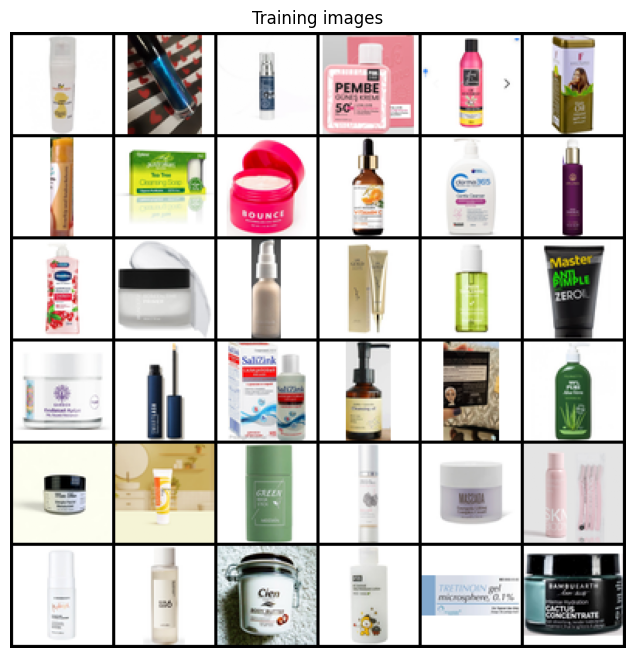

In [ ]:
class ProductImageDataset(Dataset):
    def __init__(self, paths, image_size=64):
        self.paths = paths
        self.transform = transforms.Compose([
            transforms.Resize(image_size, interpolation=transforms.InterpolationMode.BICUBIC),
            transforms.CenterCrop(image_size),
            transforms.ToTensor(),
            transforms.Normalize((0.5,)*3, (0.5,)*3)
        ])
        self.image_size = image_size

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        path = self.paths[idx]
        with Image.open(path) as im:
            im = ImageOps.exif_transpose(im).convert("RGB")
            # Fit inside square without changing aspect ratio, then pad.
            im.thumbnail((self.image_size, self.image_size), Image.Resampling.LANCZOS)
            canvas = Image.new("RGB", (self.image_size, self.image_size), (255,255,255))
            x = (self.image_size - im.width)//2
            y = (self.image_size - im.height)//2
            canvas.paste(im, (x,y))
        return self.transform(canvas)

train_ds = ProductImageDataset(train_paths, IMAGE_SIZE)
val_ds = ProductImageDataset(val_paths, IMAGE_SIZE)
test_ds = ProductImageDataset(test_paths, IMAGE_SIZE)

pin = DEVICE.type == "cuda"
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=pin, drop_last=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=pin)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=pin)

real_batch = next(iter(train_loader))
plt.figure(figsize=(8,8))
plt.imshow(make_grid((real_batch[:36]+1)/2, nrow=6).permute(1,2,0).cpu().numpy())
plt.axis("off"); plt.title("Training images"); plt.show()

In [ ]:
def sinusoidal_embedding(t, dim):
    half = dim // 2
    freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / max(half-1, 1))
    args = t[:, None] * freqs[None, :]
    emb = torch.cat([torch.sin(args), torch.cos(args)], dim=1)
    if dim % 2:
        emb = F.pad(emb, (0,1))
    return emb

In [ ]:
class ResBlock(nn.Module):
    def __init__(self, in_ch, out_ch, time_dim):
        super().__init__()
        self.norm1 = nn.GroupNorm(8, in_ch)
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.time = nn.Linear(time_dim, out_ch)
        self.norm2 = nn.GroupNorm(8, out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)
        self.skip = nn.Conv2d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()

    def forward(self, x, t_emb):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.time(F.silu(t_emb))[:, :, None, None]
        h = self.conv2(F.silu(self.norm2(h)))
        return h + self.skip(x)

In [ ]:
class TimeUNet(nn.Module):
    def __init__(self, in_channels=3, base=64, time_dim=256):
        super().__init__()
        self.time_dim = time_dim
        self.time_mlp = nn.Sequential(
            nn.Linear(time_dim, time_dim*4), nn.SiLU(),
            nn.Linear(time_dim*4, time_dim)
        )
        self.in_conv = nn.Conv2d(in_channels, base, 3, padding=1)
        self.down1 = ResBlock(base, base, time_dim)
        self.downsample1 = nn.Conv2d(base, base*2, 4, stride=2, padding=1)
        self.down2 = ResBlock(base*2, base*2, time_dim)
        self.downsample2 = nn.Conv2d(base*2, base*4, 4, stride=2, padding=1)
        self.mid1 = ResBlock(base*4, base*4, time_dim)
        self.mid2 = ResBlock(base*4, base*4, time_dim)
        self.up2 = nn.ConvTranspose2d(base*4, base*2, 4, stride=2, padding=1)
        self.up_block2 = ResBlock(base*4, base*2, time_dim)
        self.up1 = nn.ConvTranspose2d(base*2, base, 4, stride=2, padding=1)
        self.up_block1 = ResBlock(base*2, base, time_dim)
        self.out = nn.Sequential(nn.GroupNorm(8, base), nn.SiLU(), nn.Conv2d(base, 3, 3, padding=1))

    def forward(self, x, t):
        t_emb = self.time_mlp(sinusoidal_embedding(t, self.time_dim))
        x0 = self.in_conv(x)
        d1 = self.down1(x0, t_emb)
        d2 = self.down2(self.downsample1(d1), t_emb)
        h = self.mid2(self.mid1(self.downsample2(d2), t_emb), t_emb)
        h = self.up2(h)
        h = self.up_block2(torch.cat([h, d2], dim=1), t_emb)
        h = self.up1(h)
        h = self.up_block1(torch.cat([h, d1], dim=1), t_emb)
        return self.out(h)

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

In [5]:
class DDPM:
    def __init__(self, timesteps=500, beta_start=1e-4, beta_end=0.02, device=DEVICE):
        self.timesteps = timesteps
        self.device = device
        self.betas = torch.linspace(beta_start, beta_end, timesteps, device=device)
        self.alphas = 1.0 - self.betas
        self.alpha_bars = torch.cumprod(self.alphas, dim=0)
        self.sqrt_alpha_bars = torch.sqrt(self.alpha_bars)
        self.sqrt_one_minus_alpha_bars = torch.sqrt(1.0 - self.alpha_bars)

    def q_sample(self, x0, t, noise=None):
        if noise is None:
            noise = torch.randn_like(x0)
        a = self.sqrt_alpha_bars[t].view(-1,1,1,1)
        b = self.sqrt_one_minus_alpha_bars[t].view(-1,1,1,1)
        return a*x0 + b*noise, noise

    @torch.no_grad()
    def sample(self, model, n=36):
        model.eval()
        x = torch.randn(n, 3, IMAGE_SIZE, IMAGE_SIZE, device=self.device)
        for step in reversed(range(self.timesteps)):
            t = torch.full((n,), step, device=self.device, dtype=torch.long)
            eps = model(x, t.float()/max(self.timesteps-1,1))
            beta = self.betas[step]
            alpha = self.alphas[step]
            alpha_bar = self.alpha_bars[step]
            mean = (x - beta / torch.sqrt(1-alpha_bar) * eps) / torch.sqrt(alpha)
            if step > 0:
                noise = torch.randn_like(x)
                x = mean + torch.sqrt(beta) * noise
            else:
                x = mean
        return x.clamp(-1,1)

ddpm = DDPM(timesteps=500)
ddpm_model = TimeUNet().to(DEVICE)
print("DDPM parameters:", f"{count_parameters(ddpm_model):,}")

DDPM parameters: 5,398,595


In [6]:
class FlowMatching:
    def __init__(self, steps=100, device=DEVICE):
        self.steps = steps
        self.device = device

    def training_pair(self, x1):
        batch = x1.shape[0]
        eps = torch.randn_like(x1)
        t = torch.rand(batch, device=x1.device)
        t_view = t.view(batch,1,1,1)
        xt = (1.0-t_view)*eps + t_view*x1
        target_velocity = x1 - eps
        return xt, t, target_velocity

    @torch.no_grad()
    def sample(self, model, n=36):
        model.eval()
        x = torch.randn(n, 3, IMAGE_SIZE, IMAGE_SIZE, device=self.device)
        dt = 1.0/self.steps
        for i in range(self.steps):
            t = torch.full((n,), i/self.steps, device=self.device)
            velocity = model(x, t)
            x = x + dt*velocity
        return x.clamp(-1,1)

flow = FlowMatching(steps=100)
flow_model = TimeUNet().to(DEVICE)
print("Flow Matching parameters:", f"{count_parameters(flow_model):,}")

Flow Matching parameters: 5,398,595


In [ ]:
EPOCHS = 30
LEARNING_RATE = 2e-4
WEIGHT_DECAY = 0.0
SAMPLE_COUNT = 36
OUTPUT_DIR = "/content/comp8410_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

In [ ]:
def validate_ddpm(model, diffusion, loader):
    model.eval()
    losses = []
    with torch.no_grad():
        for x in loader:
            x = x.to(DEVICE)
            t = torch.randint(0, diffusion.timesteps, (x.size(0),), device=DEVICE)
            xt, noise = diffusion.q_sample(x, t)
            pred = model(xt, t.float()/max(diffusion.timesteps-1,1))
            losses.append(F.mse_loss(pred, noise).item())
    return float(np.mean(losses)) if losses else float("nan")

def validate_flow(model, flow_obj, loader):
    model.eval()
    losses = []
    with torch.no_grad():
        for x in loader:
            x = x.to(DEVICE)
            xt, t, target = flow_obj.training_pair(x)
            pred = model(xt, t)
            losses.append(F.mse_loss(pred, target).item())
    return float(np.mean(losses)) if losses else float("nan")

def train_ddpm(model, diffusion, train_loader, val_loader, epochs):
    opt = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    history = {"train_loss": [], "val_loss": []}
    scaler = torch.cuda.amp.GradScaler(enabled=(DEVICE.type=="cuda"))
    start = time.time()
    for epoch in range(epochs):
        model.train(); running=[]
        for x in train_loader:
            x = x.to(DEVICE, non_blocking=True)
            t = torch.randint(0, diffusion.timesteps, (x.size(0),), device=DEVICE)
            xt, noise = diffusion.q_sample(x, t)
            opt.zero_grad(set_to_none=True)
            with torch.cuda.amp.autocast(enabled=(DEVICE.type=="cuda")):
                pred = model(xt, t.float()/max(diffusion.timesteps-1,1))
                loss = F.mse_loss(pred, noise)
            scaler.scale(loss).backward()
            scaler.step(opt); scaler.update()
            running.append(loss.item())
        train_loss = float(np.mean(running))
        val_loss = validate_ddpm(model, diffusion, val_loader)
        history["train_loss"].append(train_loss); history["val_loss"].append(val_loss)
        print(f"DDPM | epoch {epoch+1:03d}/{epochs} | train {train_loss:.5f} | val {val_loss:.5f}")
        torch.save({"model":model.state_dict(), "history":history}, f"{OUTPUT_DIR}/ddpm_checkpoint.pt")
    history["training_minutes"] = (time.time()-start)/60
    return history

def train_flow(model, flow_obj, train_loader, val_loader, epochs):
    opt = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    history = {"train_loss": [], "val_loss": []}
    scaler = torch.cuda.amp.GradScaler(enabled=(DEVICE.type=="cuda"))
    start = time.time()
    for epoch in range(epochs):
        model.train(); running=[]
        for x in train_loader:
            x = x.to(DEVICE, non_blocking=True)
            xt, t, target = flow_obj.training_pair(x)
            opt.zero_grad(set_to_none=True)
            with torch.cuda.amp.autocast(enabled=(DEVICE.type=="cuda")):
                pred = model(xt, t)
                loss = F.mse_loss(pred, target)
            scaler.scale(loss).backward()
            scaler.step(opt); scaler.update()
            running.append(loss.item())
        train_loss = float(np.mean(running))
        val_loss = validate_flow(model, flow_obj, val_loader)
        history["train_loss"].append(train_loss); history["val_loss"].append(val_loss)
        print(f"Flow | epoch {epoch+1:03d}/{epochs} | train {train_loss:.5f} | val {val_loss:.5f}")
        torch.save({"model":model.state_dict(), "history":history}, f"{OUTPUT_DIR}/flow_checkpoint.pt")
    history["training_minutes"] = (time.time()-start)/60
    return history

In [8]:
ddpm_history = train_ddpm(ddpm_model, ddpm, train_loader, val_loader, EPOCHS)

/tmp/ipykernel_2004/3064402689.py:34: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(DEVICE.type=="cuda"))
/tmp/ipykernel_2004/3064402689.py:43: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(DEVICE.type=="cuda")):


DDPM | epoch 001/30 | train 0.80919 | val 0.44742
DDPM | epoch 002/30 | train 0.32839 | val 0.22328
DDPM | epoch 003/30 | train 0.16891 | val 0.12958
DDPM | epoch 004/30 | train 0.12897 | val 0.11665
DDPM | epoch 005/30 | train 0.11903 | val 0.10356
DDPM | epoch 006/30 | train 0.11335 | val 0.16338
DDPM | epoch 007/30 | train 0.10341 | val 0.07298
DDPM | epoch 008/30 | train 0.08785 | val 0.08996
DDPM | epoch 009/30 | train 0.09393 | val 0.07554
DDPM | epoch 010/30 | train 0.08949 | val 0.06485
DDPM | epoch 011/30 | train 0.08613 | val 0.07669
DDPM | epoch 012/30 | train 0.07762 | val 0.06040
DDPM | epoch 013/30 | train 0.08430 | val 0.09845
DDPM | epoch 014/30 | train 0.08058 | val 0.06932
DDPM | epoch 015/30 | train 0.07577 | val 0.06524
DDPM | epoch 016/30 | train 0.06813 | val 0.05899
DDPM | epoch 017/30 | train 0.06979 | val 0.07098
DDPM | epoch 018/30 | train 0.06254 | val 0.07070
DDPM | epoch 019/30 | train 0.07056 | val 0.05852
DDPM | epoch 020/30 | train 0.06270 | val 0.06757


In [9]:
flow_history = train_flow(flow_model, flow, train_loader, val_loader, EPOCHS)

/tmp/ipykernel_2004/3064402689.py:60: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(DEVICE.type=="cuda"))
/tmp/ipykernel_2004/3064402689.py:68: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(DEVICE.type=="cuda")):


Flow | epoch 001/30 | train 1.05473 | val 0.76773
Flow | epoch 002/30 | train 0.60325 | val 0.47000
Flow | epoch 003/30 | train 0.40779 | val 0.35641
Flow | epoch 004/30 | train 0.32607 | val 0.29535
Flow | epoch 005/30 | train 0.28829 | val 0.28521
Flow | epoch 006/30 | train 0.28893 | val 0.24084
Flow | epoch 007/30 | train 0.26628 | val 0.25544
Flow | epoch 008/30 | train 0.25452 | val 0.24321
Flow | epoch 009/30 | train 0.24193 | val 0.20673
Flow | epoch 010/30 | train 0.23289 | val 0.21420
Flow | epoch 011/30 | train 0.22362 | val 0.21737
Flow | epoch 012/30 | train 0.22417 | val 0.20023
Flow | epoch 013/30 | train 0.20556 | val 0.18590
Flow | epoch 014/30 | train 0.20550 | val 0.23351
Flow | epoch 015/30 | train 0.24368 | val 0.25027
Flow | epoch 016/30 | train 0.23104 | val 0.22154
Flow | epoch 017/30 | train 0.21971 | val 0.19881
Flow | epoch 018/30 | train 0.19630 | val 0.18324
Flow | epoch 019/30 | train 0.18643 | val 0.19809
Flow | epoch 020/30 | train 0.18883 | val 0.19250


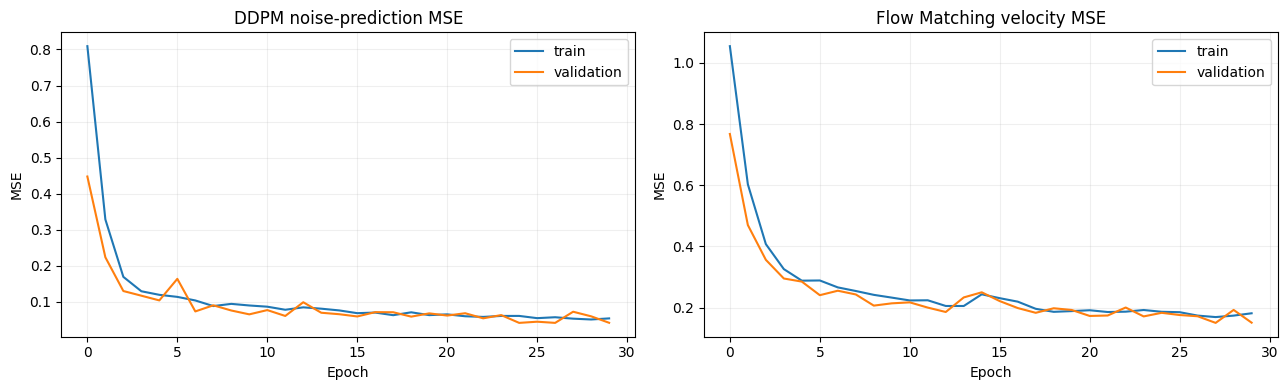

In [10]:
fig, axes = plt.subplots(1,2,figsize=(13,4))
for ax, hist, title in [
    (axes[0], ddpm_history, "DDPM noise-prediction MSE"),
    (axes[1], flow_history, "Flow Matching velocity MSE")
]:
    ax.plot(hist["train_loss"], label="train")
    ax.plot(hist["val_loss"], label="validation")
    ax.set_title(title); ax.set_xlabel("Epoch"); ax.set_ylabel("MSE")
    ax.legend(); ax.grid(alpha=.2)
plt.tight_layout(); plt.savefig(f"{OUTPUT_DIR}/training_curves.png", dpi=150); plt.show()

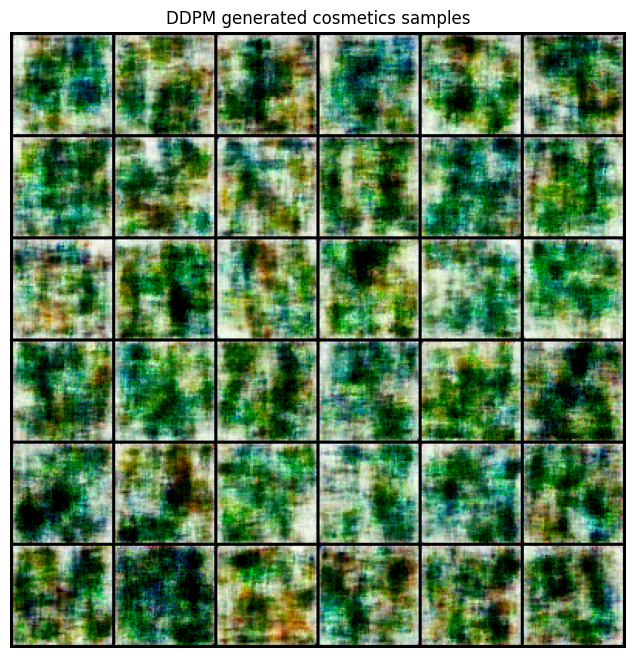

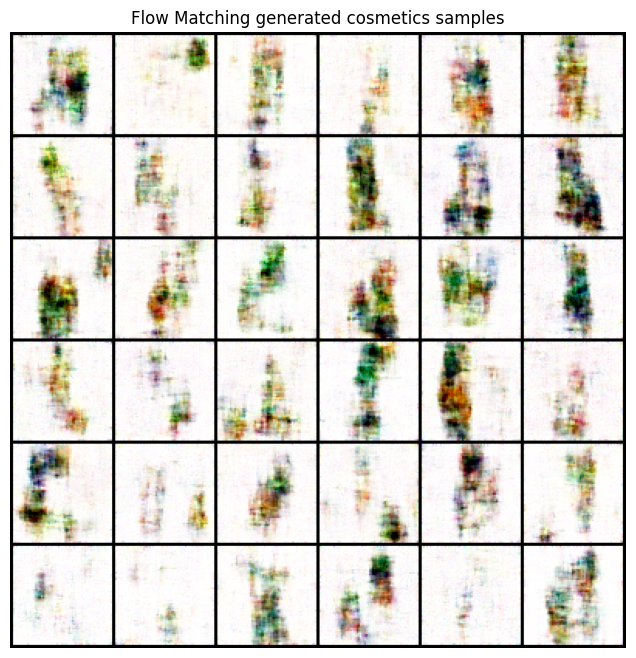

In [11]:
ddpm_samples = ddpm.sample(ddpm_model, SAMPLE_COUNT)
flow_samples = flow.sample(flow_model, SAMPLE_COUNT)

save_image((ddpm_samples+1)/2, f"{OUTPUT_DIR}/ddpm_samples.png", nrow=6)
save_image((flow_samples+1)/2, f"{OUTPUT_DIR}/flow_matching_samples.png", nrow=6)

def show_samples(samples, title):
    grid = make_grid((samples[:36]+1)/2, nrow=6)
    plt.figure(figsize=(8,8))
    plt.imshow(grid.permute(1,2,0).cpu().numpy())
    plt.title(title); plt.axis("off"); plt.show()

show_samples(ddpm_samples, "DDPM generated cosmetics samples")
show_samples(flow_samples, "Flow Matching generated cosmetics samples")

In [12]:
ddpm_test_mse = validate_ddpm(ddpm_model, ddpm, test_loader)
flow_test_mse = validate_flow(flow_model, flow, test_loader)
summary = {
    "dataset_images": len(valid_paths),
    "train_images": len(train_ds),
    "validation_images": len(val_ds),
    "test_images": len(test_ds),
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "epochs": EPOCHS,
    "ddpm_timesteps": ddpm.timesteps,
    "flow_euler_steps": flow.steps,
    "ddpm_test_noise_mse": ddpm_test_mse,
    "flow_test_velocity_mse": flow_test_mse,
    "ddpm_training_minutes": ddpm_history["training_minutes"],
    "flow_training_minutes": flow_history["training_minutes"]
}
with open(f"{OUTPUT_DIR}/experiment_summary.json","w") as f:
    json.dump(summary, f, indent=2)
print(json.dumps(summary, indent=2))

{
  "dataset_images": 1000,
  "train_images": 800,
  "validation_images": 100,
  "test_images": 100,
  "image_size": 64,
  "batch_size": 64,
  "epochs": 30,
  "ddpm_timesteps": 500,
  "flow_euler_steps": 100,
  "ddpm_test_noise_mse": 0.0357979591935873,
  "flow_test_velocity_mse": 0.16417411714792252,
  "ddpm_training_minutes": 1.553661855061849,
  "flow_training_minutes": 1.5100413997968039
}


In [13]:
torch.save(ddpm_model.state_dict(), f"{OUTPUT_DIR}/ddpm_final.pth")
torch.save(flow_model.state_dict(), f"{OUTPUT_DIR}/flow_matching_final.pth")
archive = shutil.make_archive("/content/COMP8410_DDPM_FlowMatching_results", "zip", OUTPUT_DIR)
print("Saved:", archive)

# In Google Colab, uncomment to download:
from google.colab import files
files.download(archive)

Saved: /content/COMP8410_DDPM_FlowMatching_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>